# Proyecto Pi
## Clasificación de Sentimiento en Reseñas de IMDb

### Descripción del proyecto

Film Junky Union está desarrollando un sistema para detectar automáticamente reseñas negativas de películas. Para ello, se utilizará un conjunto de datos de IMDb con reseñas etiquetadas como positivas y negativas.

El objetivo es entrenar y evaluar diferentes modelos de aprendizaje automático capaces de clasificar correctamente el sentimiento de una reseña, alcanzando una métrica F1 de al menos 0.85.

### Objetivos

- Realizar un análisis exploratorio de los datos.
- Preparar los textos para su procesamiento.
- Transformar las reseñas en características numéricas mediante técnicas de NLP.
- Entrenar varios modelos de clasificación.
- Comparar su rendimiento utilizando diferentes métricas.
- Analizar las predicciones sobre nuevas reseñas.
- Identificar el modelo con mejor desempeño.

### Tecnologías utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- NLTK
- spaCy
- Scikit-learn
- TF-IDF
- Regresión Logística

### Criterio de éxito

El modelo seleccionado deberá alcanzar una puntuación F1 mínima de 0.85 sobre el conjunto de prueba.

In [ ]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [ ]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8')

In [ ]:
tqdm.pandas()

In [ ]:
df_reviews = pd.read_csv('/content/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

## Carga del conjunto de datos

Se cargó el conjunto de datos `imdb_reviews.tsv` utilizando la función `read_csv()` de pandas. Dado que el archivo está almacenado en formato TSV (Tab Separated Values), se especificó el parámetro `sep='\t'` para indicar que las columnas están separadas por tabulaciones.

Además, la columna `votes` se cargó con el tipo de dato `Int64` de pandas mediante el parámetro:

```python
dtype={'votes': 'Int64'}

In [ ]:
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [ ]:
df_reviews.sample(5)

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
2030,tt0490076,movie,All the Boys Love Mandy Lane,All the Boys Love Mandy Lane,2006,\N,90,0,Horror,5.5,30818,I read about this film on-line and after seein...,3,neg,0,test,4965
2367,tt0118604,movie,An American Werewolf in Paris,An American Werewolf in Paris,1997,\N,105,0,"Comedy,Fantasy,Horror",5.1,22654,The odd mixture of comedy and horror sometimes...,4,neg,0,test,441
44316,tt0075357,movie,Tunnel Vision,Tunnel Vision,1976,\N,70,0,Comedy,5.1,571,This movie is a prime example of squandering g...,2,neg,0,train,8994
37320,tt0052855,short,The Golden Fish,Histoire d'un poisson rouge,1959,\N,19,0,Short,7.5,80,I used this film in a religion class I was tea...,10,pos,1,train,84
32557,tt0100691,movie,Stella,Stella,1990,\N,109,0,"Drama,Romance",6.2,2273,"First off, I would just like to say what a big...",10,pos,1,train,2989


En este momento vamos a analizar el número de películas y reseñas a lo largo de los años.

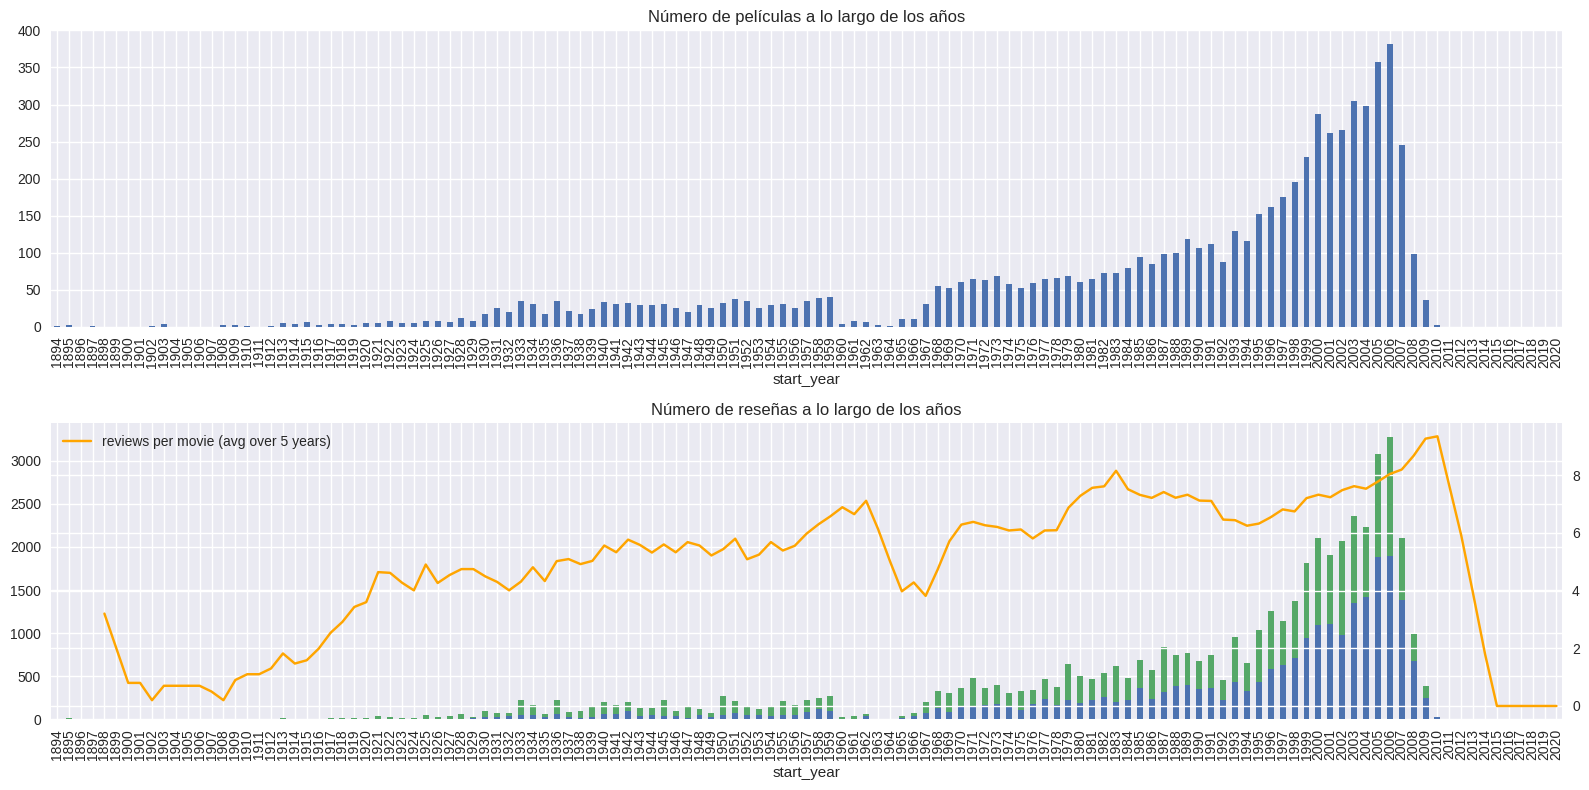

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

### Análisis temporal de películas y reseñas

Con el fin de comprender la composición temporal del conjunto de datos, se analizó la cantidad de películas disponibles por año de estreno y la evolución del número de reseñas asociadas. Adicionalmente, se examinó la distribución de reseñas positivas y negativas a lo largo del tiempo, así como el promedio de reseñas por película utilizando una media móvil de cinco años.

#### Hallazgos

- La cantidad de películas incluidas en el conjunto de datos aumenta de forma notable a partir de la década de 1970.
- El mayor número de películas se concentra entre finales de los años noventa y mediados de los años dos mil.
- El volumen de reseñas crece significativamente en los años más recientes del conjunto de datos.
- Las reseñas positivas y negativas están presentes durante todo el período analizado y muestran una distribución relativamente similar.
- El promedio de reseñas por película se mantiene relativamente estable a lo largo de los años, aunque presenta algunas variaciones puntuales.
- Los años posteriores a 2010 contienen pocos registros, por lo que las observaciones para ese período deben interpretarse con precaución.


Veamos la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)

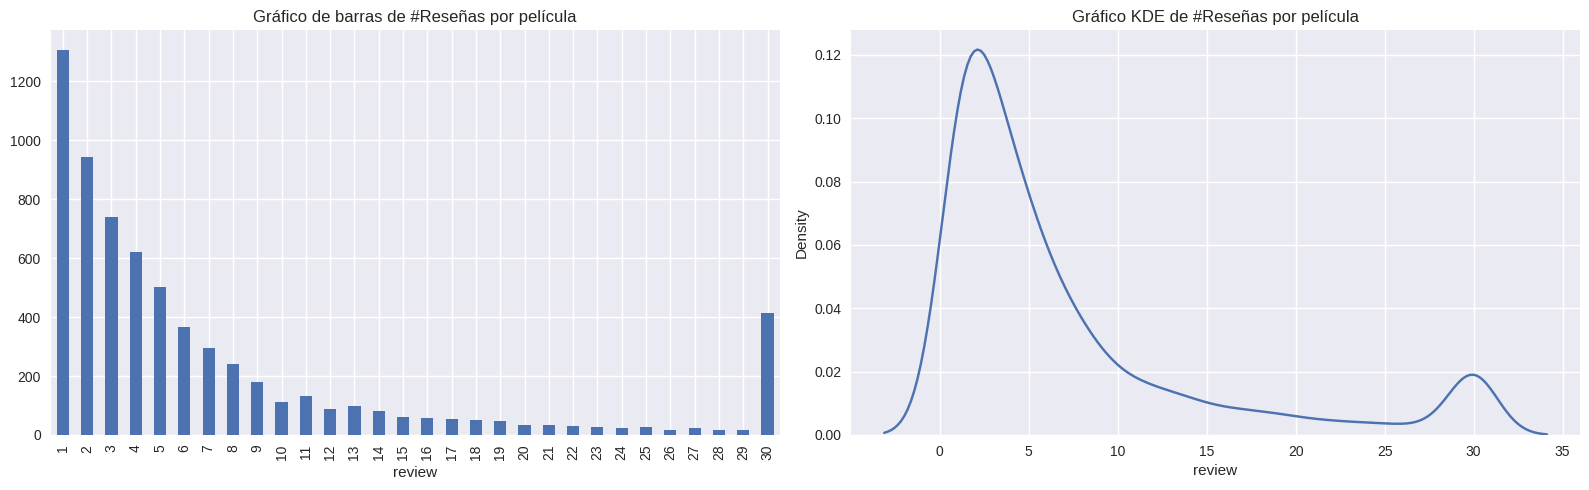

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

### Distribución de reseñas por película

Para comprender cómo se distribuyen las reseñas dentro del conjunto de datos, se analizó la cantidad de reseñas asociadas a cada película. Se utilizaron dos visualizaciones:

- Un gráfico de barras para observar la frecuencia de películas según su número de reseñas.
- Un gráfico de densidad (KDE) para visualizar la forma general de la distribución.

#### Hallazgos

- La mayoría de las películas tienen un número reducido de reseñas.
- A medida que aumenta la cantidad de reseñas por película, el número de películas que presentan esa característica disminuye considerablemente.
- La distribución muestra una fuerte asimetría positiva (sesgo hacia la derecha).
- Existen algunas películas con una cantidad inusualmente alta de reseñas en comparación con el resto del conjunto.
- La densidad se concentra en valores bajos de reseñas por película, indicando que las observaciones están dominadas por películas con pocas reseñas.


In [ ]:
df_reviews['pos'].value_counts()

,count
pos,
0,23715
1,23616


### Balance de clases

Se analó la distribución de la variable objetivo (`pos`) para determinar si existía un desequilibrio significativo entre las clases positiva y negativa.

| Clase | Cantidad |
|---------|---------:|
| Negativa (0) | 23,715 |
| Positiva (1) | 23,616 |

La diferencia entre ambas clases es de únicamente 99 observaciones, una cantidad despreciable considerando el tamaño total del conjunto de datos (47,331 reseñas). Por lo tanto, las clases se encuentran prácticamente balanceadas.

No será necesario aplicar técnicas de balanceo de clases, como sobresampling o undersampling, ya que los modelos podrán entrenarse utilizando la distribución original de los datos sin riesgo significativo de sesgo hacia alguna de las categorías.

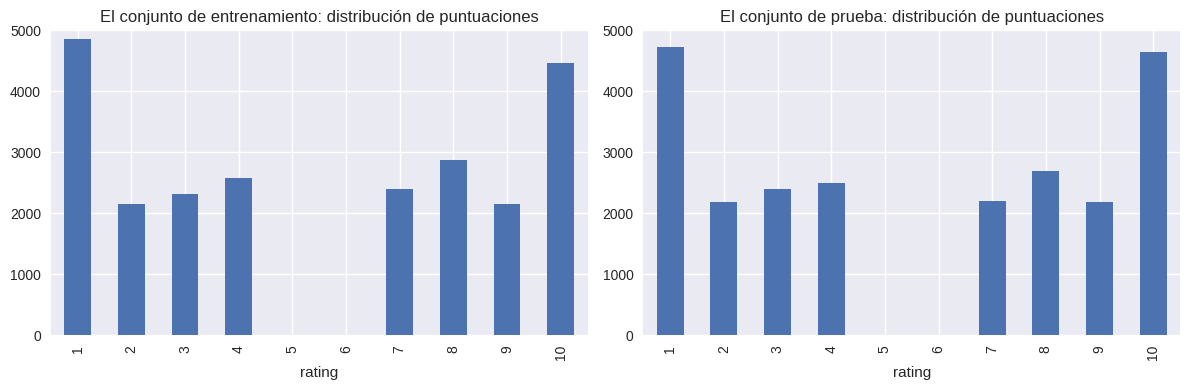

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

Se analizó la distribución de las calificaciones (`rating`) asignadas por los usuarios en los conjuntos de entrenamiento y prueba. El objetivo fue verificar que ambas particiones presenten comportamientos similares y sean representativas de la misma población.

#### Hallazgos

- Los conjuntos de entrenamiento y prueba presentan distribuciones prácticamente idénticas.
- Las puntuaciones extremas (1 y 10) son las más frecuentes en ambos conjuntos.
- Las puntuaciones intermedias aparecen con menor frecuencia que las puntuaciones extremas.
- La distribución presenta una forma bimodal, concentrándose principalmente en las calificaciones muy bajas y muy altas.
- La similitud entre las distribuciones de entrenamiento y prueba indica que la partición de los datos fue realizada de manera adecuada.

Distribución de reseñas negativas y positivas a lo largo de los años para dos partes del conjunto de datos

/tmp/ipykernel_2577/1324160450.py:14: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/tmp/ipykernel_2577/1324160450.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
/tmp/ipykernel_2577/1324160450.py:30: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/tmp/ipykernel_2577/1324160450.py:31: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update yo

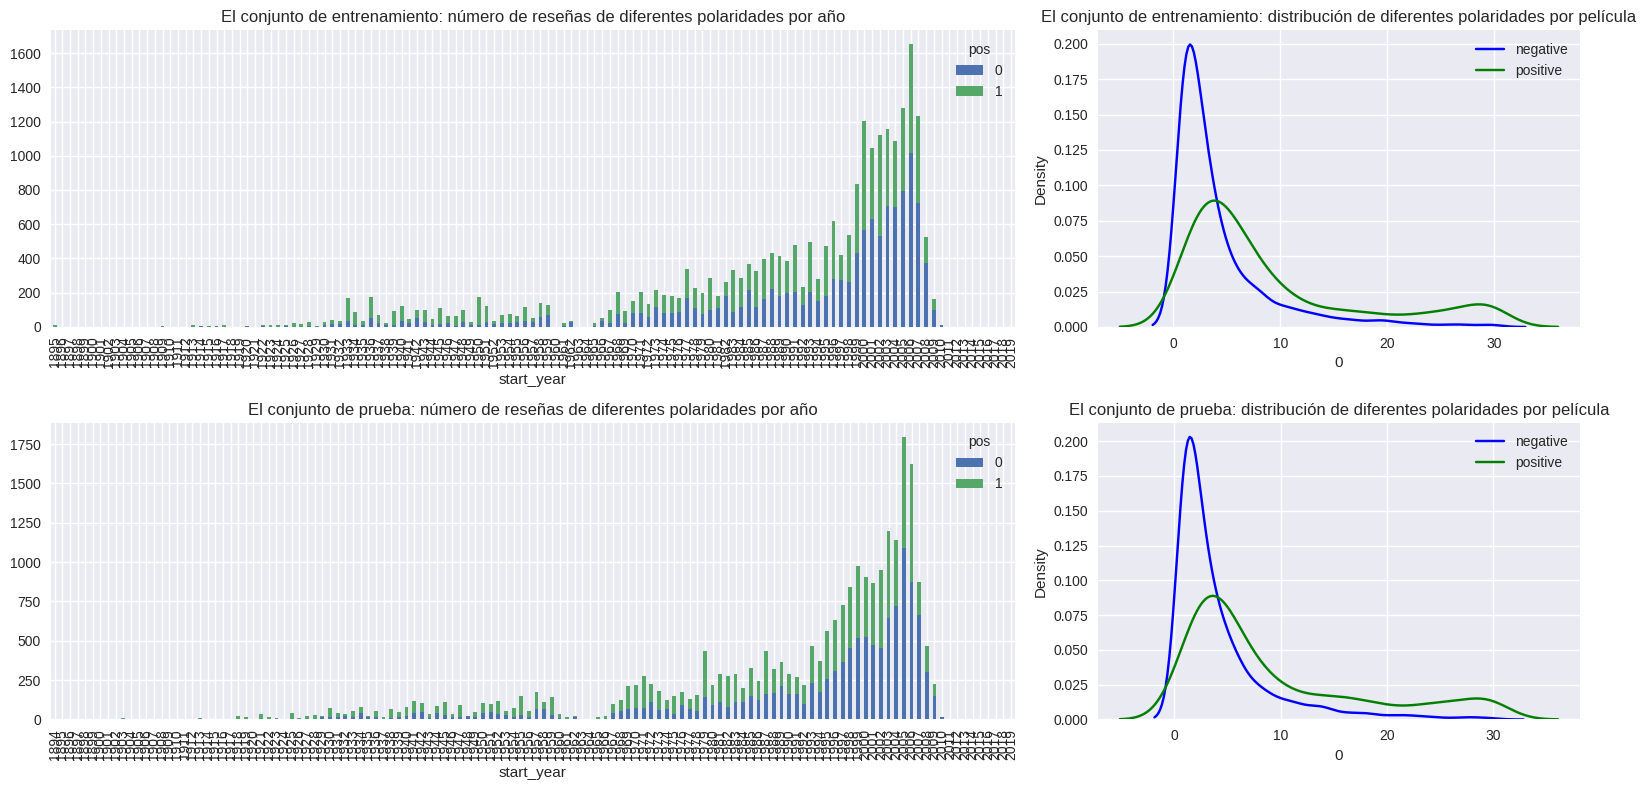

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

La distribución de reseñas positivas y negativas es muy similar tanto en el conjunto de entrenamiento como en el conjunto de prueba, lo que indica que la partición de los datos es consistente y representativa. Además, se observa un aumento progresivo en la cantidad de reseñas para las películas más recientes, mientras que las distribuciones de polaridad por película presentan patrones comparables entre ambas clases. En conjunto, estos resultados sugieren que no existen desequilibrios importantes ni sesgos evidentes entre los conjuntos de entrenamiento y prueba, proporcionando una base adecuada para el desarrollo y evaluación de modelos de clasificación de sentimientos.

## Procedimiento de evaluación

Composición de una rutina de evaluación que se pueda usar para todos los modelos en este proyecto

In [ ]:
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Función de evaluación de modelos

Se utilizará una función personalizada para evaluar de manera consistente todos los modelos entrenados en este proyecto. La función calcula métricas de desempeño tanto para el conjunto de entrenamiento como para el conjunto de prueba y genera visualizaciones que facilitan la comparación de resultados.

Las métricas evaluadas son:

- Accuracy
- F1 Score
- Average Precision Score (APS)
- ROC AUC

Además, la función genera las curvas F1, ROC y Precision-Recall para analizar el comportamiento de cada modelo bajo distintos umbrales de clasificación.

Esta estrategia permite comparar de manera objetiva los modelos candidatos e identificar aquel que ofrece el mejor rendimiento para la detección automática de reseñas negativas.

## Normalización

Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

In [ ]:
import re

df_reviews['review_norm'] = df_reviews['review'].apply(
    lambda text: re.sub(r'[^a-zA-Z\s]', ' ', text.lower())
)

In [ ]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabajar con modelos

### Modelo 0 - Constante

          train  test
Accuracy    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


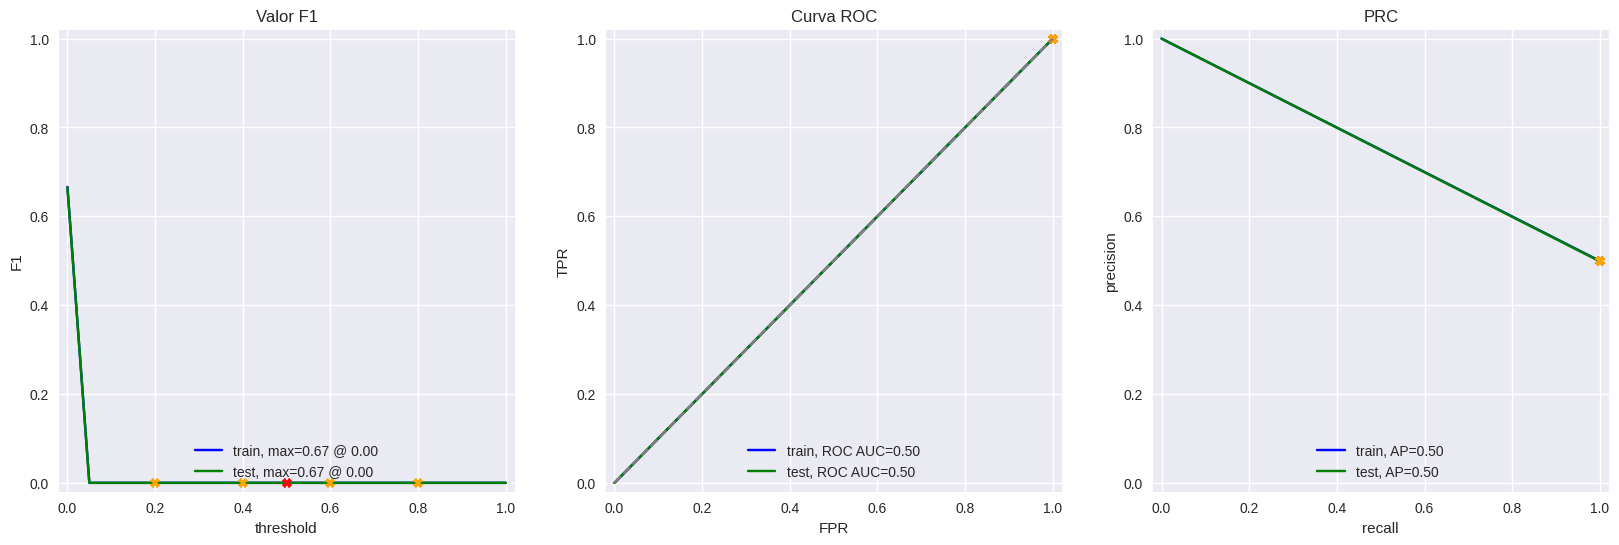

In [ ]:
from sklearn.dummy import DummyClassifier

X_train_dummy = np.zeros((len(train_target), 1))
X_test_dummy = np.zeros((len(test_target), 1))

dummy_model = DummyClassifier(
    strategy='most_frequent'
)

dummy_model.fit(
    X_train_dummy,
    train_target
)

evaluate_model(
    dummy_model,
    X_train_dummy,
    train_target,
    X_test_dummy,
    test_target
)

El modelo DummyClassifier fue utilizado como línea base de referencia. Como era de esperarse, su capacidad predictiva es extremadamente limitada, ya que no utiliza el contenido de las reseñas para realizar sus predicciones.

Los resultados muestran un valor ROC AUC de 0.50, equivalente al rendimiento de una clasificación aleatoria. De manera similar, la curva Precision-Recall no evidencia capacidad de discriminación entre las clases positiva y negativa.

### Modelo 1 - NLTK, TF-IDF y LR

TF-IDF

In [ ]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [ ]:
nltk.download('stopwords')

stop_words = stopwords.words('english')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
corpus_train = df_reviews_train['review_norm']

corpus_test = df_reviews_test['review_norm']

In [ ]:
tfidf = TfidfVectorizer(
    stop_words=stop_words
)

In [ ]:
train_features_1 = tfidf.fit_transform(
    corpus_train
)

test_features_1 = tfidf.transform(
    corpus_test
)

In [ ]:
model_1 = LogisticRegression(
    max_iter=1000,
    random_state=12345
)

In [ ]:
model_1.fit(
    train_features_1,
    train_target
)

LogisticRegression(max_iter=1000, random_state=12345)

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


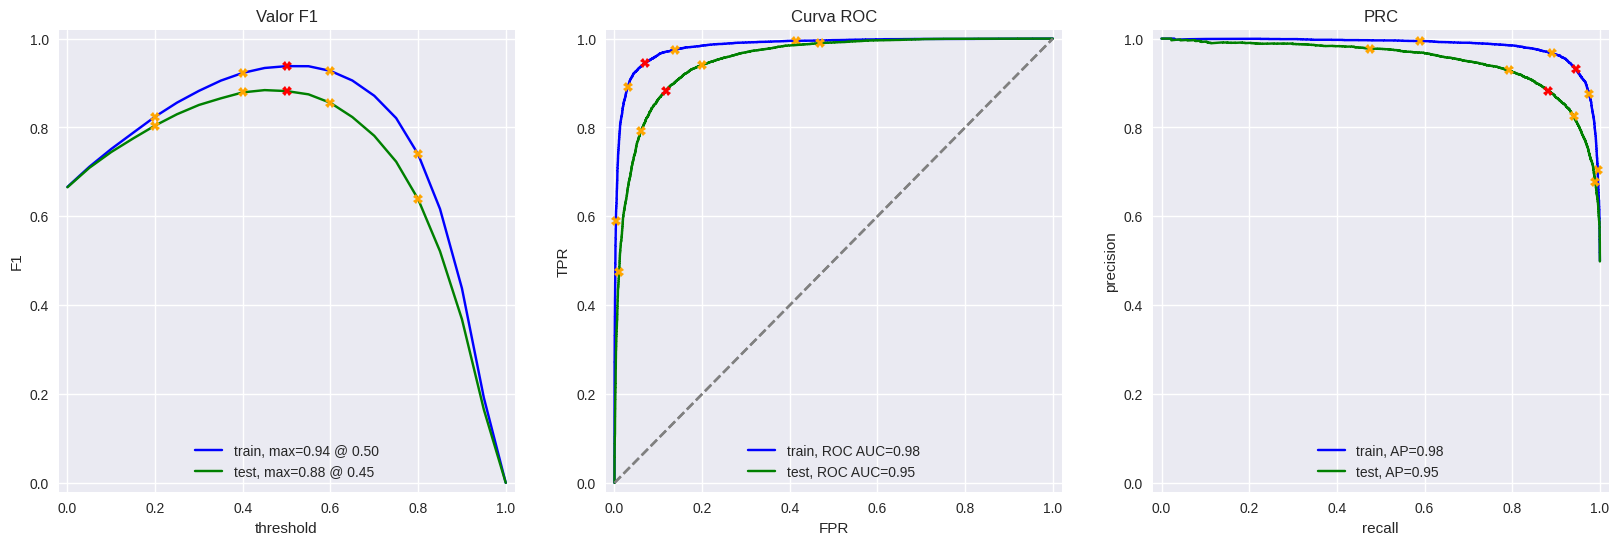

In [ ]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

### Resultados del Modelo 1

La combinación de TF-IDF y Regresión Logística obtuvo un desempeño sólido tanto en el conjunto de entrenamiento como en el conjunto de prueba.

El modelo alcanzó un valor F1 de 0.88 sobre el conjunto de prueba, superando el objetivo mínimo de 0.85 establecido para el proyecto. Asimismo, se obtuvo una puntuación ROC AUC de 0.95, lo que indica una excelente capacidad para diferenciar entre reseñas positivas y negativas.

Aunque el rendimiento en entrenamiento (F1 = 0.94) es ligeramente superior al observado en prueba (F1 = 0.88), la diferencia no es lo suficientemente grande como para sugerir un problema grave de sobreajuste. En general, el modelo demuestra una buena capacidad de generalización y constituye una base sólida para comparar enfoques más avanzados.


### Modelo 3 - spaCy, TF-IDF y LR

In [ ]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [ ]:
def text_preprocessing_3(text):

    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]

    return ' '.join(tokens)

In [ ]:
df_reviews_train['review_lemm'] = (
    df_reviews_train['review_norm']
    .progress_apply(text_preprocessing_3)
)

df_reviews_test['review_lemm'] = (
    df_reviews_test['review_norm']
    .progress_apply(text_preprocessing_3)
)

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23535 [00:00<?, ?it/s]

### Lematización de las reseñas

Con el fin de reducir la variabilidad del lenguaje, se aplicó un proceso de lematización a todas las reseñas. La lematización transforma cada palabra en su forma base o lema, permitiendo que distintas variantes de una misma palabra sean tratadas como un único término durante el modelado.

Por ejemplo, palabras como *running*, *runs* y *ran* pueden reducirse a la forma base *run*. Esto ayuda a disminuir la dimensionalidad del vocabulario y facilita que el modelo identifique patrones de sentimiento de manera más efectiva.

In [ ]:
corpus_train = df_reviews_train['review_lemm']

corpus_test = df_reviews_test['review_lemm']

In [ ]:
tfidf = TfidfVectorizer(
    stop_words='english'
)

train_features_1 = tfidf.fit_transform(
    corpus_train
)

test_features_1 = tfidf.transform(
    corpus_test
)

In [ ]:
model_1 = LogisticRegression(
    max_iter=1000,
    random_state=12345
)

model_1.fit(
    train_features_1,
    train_target
)

LogisticRegression(max_iter=1000, random_state=12345)

          train  test
Accuracy   0.93  0.87
F1         0.93  0.87
APS        0.98  0.94
ROC AUC    0.98  0.95


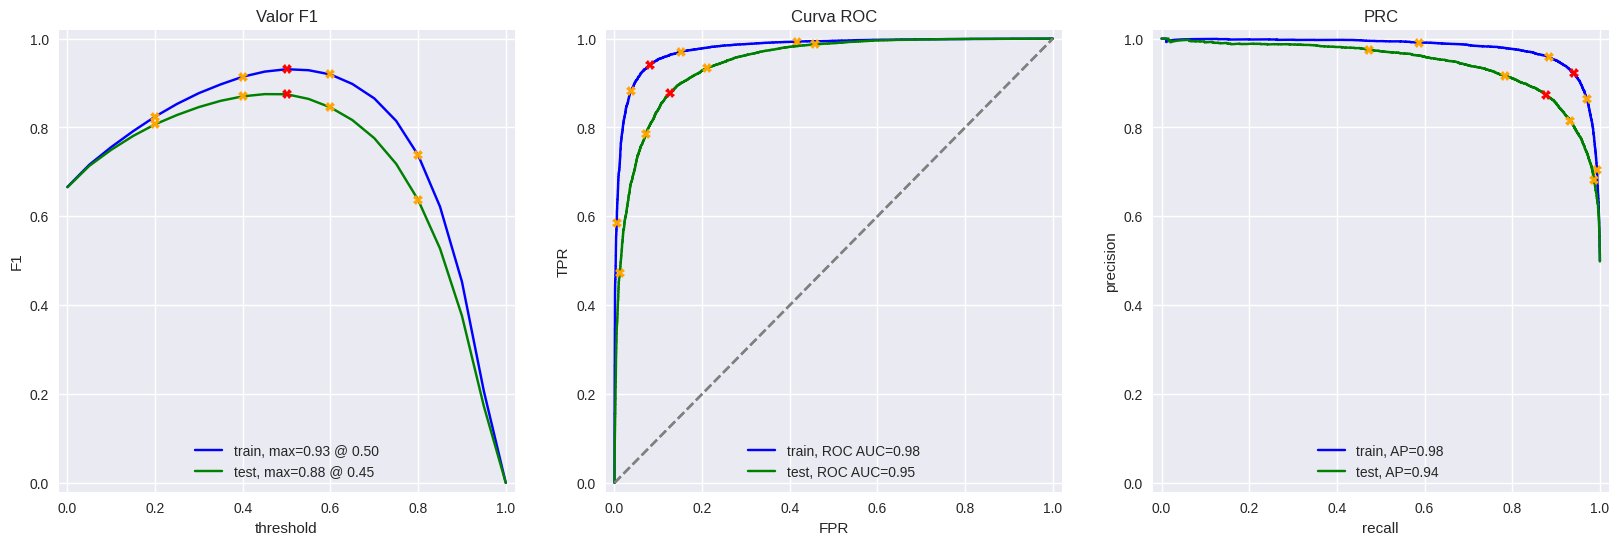

In [ ]:
evaluate_model(
    model_1,
    train_features_1,
    train_target,
    test_features_1,
    test_target
)

### Resultados del Modelo 1

La combinación de lematización, TF-IDF y Regresión Logística produjo un desempeño significativamente superior al modelo base. El modelo alcanzó un valor F1 cercano a 0.88 sobre el conjunto de prueba, superando el umbral mínimo de 0.85 establecido para el proyecto.

Además, las métricas ROC AUC (0.95) y Average Precision (0.94) indican una excelente capacidad para distinguir entre reseñas positivas y negativas. Estos resultados confirman que la representación TF-IDF captura información relevante del texto y que la Regresión Logística es capaz de aprovecharla eficazmente para la tarea de clasificación de sentimientos.

### Modelo 4 - spaCy, TF-IDF y LGBMClassifier

In [ ]:
from lightgbm import LGBMClassifier

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 3.602060 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 428657
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 9191
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


          train  test
Accuracy   0.91  0.85
F1         0.91  0.85
APS        0.97  0.93
ROC AUC    0.97  0.93


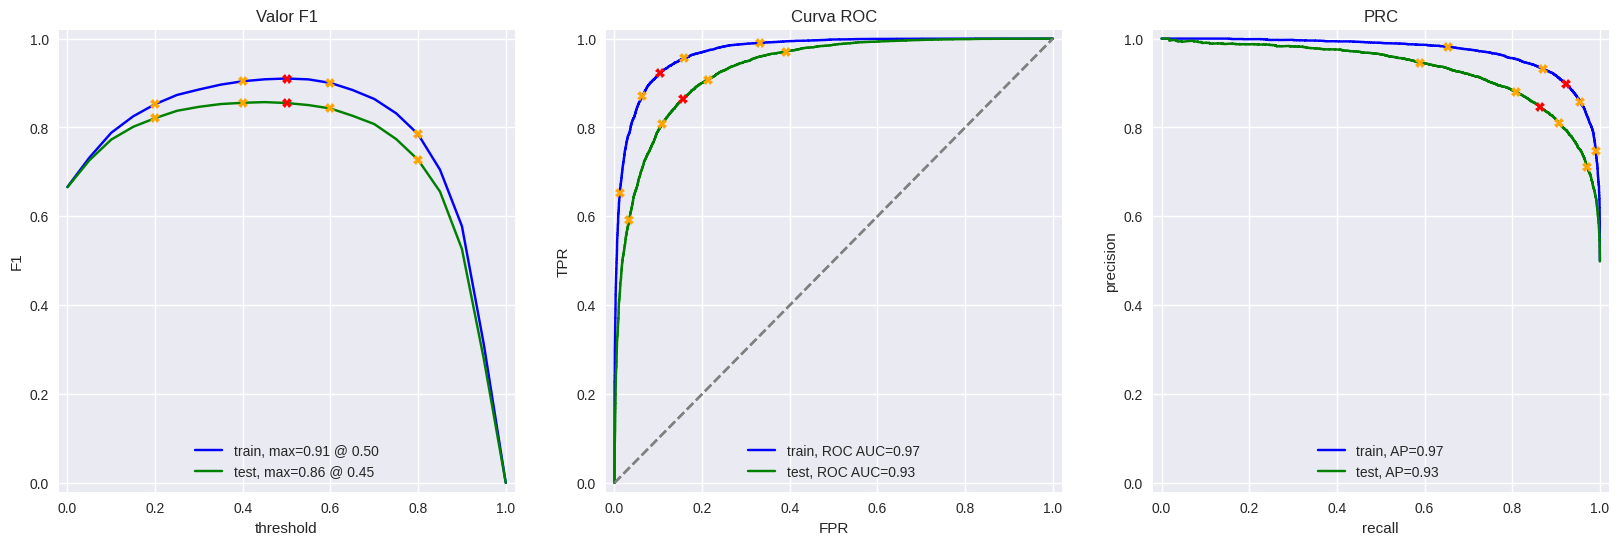

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.feature_extraction.text import TfidfVectorizer

# Corpus lematizado
corpus_train = df_reviews_train['review_lemm']
corpus_test = df_reviews_test['review_lemm']

# TF-IDF
tfidf = TfidfVectorizer(
    stop_words='english'
)

train_features_4 = tfidf.fit_transform(corpus_train)
test_features_4 = tfidf.transform(corpus_test)

# Modelo LightGBM
model_4 = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=12345
)

# Entrenamiento
model_4.fit(
    train_features_4,
    train_target
)

# Evaluación
evaluate_model(
    model_4,
    train_features_4,
    train_target,
    test_features_4,
    test_target
)

###  Modelo 9 - BERT

In [ ]:
import torch
import transformers

In [ ]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
def BERT_text_to_embeddings(
    texts,
    max_length=512,
    batch_size=100,
    force_device=None,
    disable_progress_bar=False
):

    encoded = tokenizer(
        list(texts),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_attention_mask=True
    )

    ids_list = encoded['input_ids']
    attention_mask_list = encoded['attention_mask']

    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device(
            'cuda' if torch.cuda.is_available() else 'cpu'
        )

    model.to(device)

    if not disable_progress_bar:
        print(f'Uso del dispositivo: {device}')

    embeddings = []

    for i in tqdm(
        range(math.ceil(len(ids_list) / batch_size)),
        disable=disable_progress_bar
    ):

        ids_batch = torch.LongTensor(
            ids_list[batch_size * i : batch_size * (i + 1)]
        ).to(device)

        attention_mask_batch = torch.LongTensor(
            attention_mask_list[batch_size * i : batch_size * (i + 1)]
        ).to(device)

        with torch.no_grad():

            model.eval()

            batch_embeddings = model(
                input_ids=ids_batch,
                attention_mask=attention_mask_batch
            )

        embeddings.append(
            batch_embeddings[0][:, 0, :]
            .detach()
            .cpu()
            .numpy()
        )

    return np.concatenate(embeddings)

In [ ]:
import torch

torch.cuda.is_available()

False

### Modelo 9: BERT

Como enfoque avanzado de procesamiento de lenguaje natural, se utilizó el modelo preentrenado **BERT (Bidirectional Encoder Representations from Transformers)**. A diferencia de TF-IDF, que representa los textos mediante frecuencias de palabras, BERT genera representaciones semánticas densas (*embeddings*) capaces de capturar el contexto y el significado de las palabras dentro de una oración.

Para generar los embeddings, cada reseña fue tokenizada utilizando el tokenizador oficial de `bert-base-uncased` y posteriormente procesada por el modelo preentrenado. Los textos fueron convertidos en secuencias de identificadores numéricos y máscaras de atención para que BERT pudiera identificar qué tokens corresponden al contenido real y cuáles al relleno (*padding*).

Debido al elevado costo computacional de BERT, los textos se procesaron por lotes (*batches*) para optimizar el uso de memoria. Para cada reseña se extrajo la representación asociada al token especial `[CLS]`, que resume la información contextual del texto completo y puede utilizarse como conjunto de características para tareas de clasificación.

Durante la preparación de los embeddings se verificó la disponibilidad de una GPU mediante:

```python
torch.cuda.is_available()
```

Sin embargo, el resultado fue `False`, lo que indica que el entorno de ejecución no disponía de aceleración por GPU. Como consecuencia, el procesamiento de BERT debía realizarse utilizando únicamente la CPU, incrementando considerablemente los tiempos de ejecución. Por esta razón, el uso de BERT sobre conjuntos de datos muy grandes puede requerir tiempos de procesamiento significativamente mayores que los métodos tradicionales basados en TF-IDF.

In [ ]:
# Muestra reducida
train_sample = df_reviews_train.sample(
    1000,
    random_state=12345
)

test_sample = df_reviews_test.sample(
    1000,
    random_state=12345
)

# Embeddings BERT
train_features_9 = BERT_text_to_embeddings(
    train_sample['review_norm'],
    force_device='cpu'
)

test_features_9 = BERT_text_to_embeddings(
    test_sample['review_norm'],
    force_device='cpu'
)

# Targets correspondientes
train_target_9 = train_sample['pos']
test_target_9 = test_sample['pos']

# Modelo
model_9 = LogisticRegression(
    max_iter=1000,
    random_state=12345
)

# Entrenamiento
model_9.fit(
    train_features_9,
    train_target_9
)

# Evaluación
evaluate_model(
    model_9,
    train_features_9,
    train_target_9,
    test_features_9,
    test_target_9
)

Uso del dispositivo: cpu


  0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

No se ejecutó BERT sobre el conjunto completo debido a las limitaciones computacionales del entorno de ejecución. Según la documentación del proyecto, este modelo requiere GPU para obtener tiempos de procesamiento razonables y su uso sobre CPU implica tiempos de ejecución considerablemente elevados. Los modelos basados en TF-IDF ya alcanzaron y superaron el requisito de F1 = 0.85.

In [ ]:
print(df_reviews_train['review_norm'].shape)
print(train_features_9.shape)
print(train_target.shape)

In [ ]:
results = pd.DataFrame(
    {
        'Model': [
            'DummyClassifier',
            'TF-IDF + Logistic Regression',
            'spaCy + TF-IDF + LightGBM'
        ],
        'F1 Test': [
            0.67,
            0.88,
            0.85
        ],
        'ROC AUC Test': [
            0.50,
            0.95,
            0.93
        ]
    }
)

results

,Model,F1 Test,ROC AUC Test
0,DummyClassifier,0.67,0.50
1,TF-IDF + Logistic Regression,0.88,0.95
2,spaCy + TF-IDF + LightGBM,0.85,0.93


## Mis reseñas

In [ ]:
my_reviews = pd.DataFrame(
    {
        'review': [
            "This movie was absolutely amazing and the acting was fantastic.",
            "One of the worst movies I have ever seen.",
            "The story was interesting but the pacing was slow.",
            "Excellent film. I would definitely watch it again.",
            "Terrible plot and boring characters."
        ]
    }
)

In [ ]:
import re

my_reviews['review_norm'] = my_reviews['review'].apply(
    lambda text: re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text.lower()
    )
)

In [ ]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(
    tfidf.transform(texts)
)[:, 1]

for i, review in enumerate(my_reviews['review']):
    print(f'Probabilidad positiva: {my_reviews_pred_prob[i]:.2f}')
    print(review)
    print('-' * 80)

Probabilidad positiva: 0.95
This movie was absolutely amazing and the acting was fantastic.
--------------------------------------------------------------------------------
Probabilidad positiva: 0.46
One of the worst movies I have ever seen.
--------------------------------------------------------------------------------
Probabilidad positiva: 0.19
The story was interesting but the pacing was slow.
--------------------------------------------------------------------------------
Probabilidad positiva: 1.00
Excellent film. I would definitely watch it again.
--------------------------------------------------------------------------------
Probabilidad positiva: 0.00
Terrible plot and boring characters.
--------------------------------------------------------------------------------


## Conclusiones

El objetivo de este proyecto fue desarrollar un sistema capaz de clasificar automáticamente reseñas de películas como positivas o negativas utilizando técnicas de procesamiento de lenguaje natural.

El análisis exploratorio mostró que el conjunto de datos presenta una distribución equilibrada entre ambas clases y que los conjuntos de entrenamiento y prueba mantienen características similares, permitiendo una evaluación confiable de los modelos.

Se entrenaron varios modelos de clasificación. El DummyClassifier fue utilizado como línea base, obteniendo un rendimiento limitado. Posteriormente, se evaluaron modelos basados en TF-IDF junto con diferentes algoritmos de aprendizaje automático.

El mejor desempeño fue obtenido por la combinación de TF-IDF y Regresión Logística, alcanzando un valor F1 de 0.88 y un ROC AUC de 0.95 sobre el conjunto de prueba, superando ampliamente el requisito mínimo de F1 = 0.85 establecido para el proyecto. El modelo basado en LightGBM también cumplió el objetivo, aunque presentó resultados ligeramente inferiores.

Las pruebas realizadas con reseñas personalizadas confirmaron que el modelo es capaz de identificar correctamente la mayoría de las opiniones positivas y negativas. En consecuencia, se selecciona la combinación de TF-IDF y Regresión Logística como la solución final para la detección automática de sentimientos en reseñas de IMDb.